# Data Science Project 3: Unsupervised Learning (Customer Segmentation)

**DecodeLabs Industrial Training Kit | Batch 2026**
**Author:** Shifat Rahman Kabbo

---

## Pipeline: SCALE → COMPRESS (PCA) → CLUSTER (K-Means) → TRANSLATE (Personas)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("✅ All libraries imported")

✅ All libraries imported


## Step 1: Load Dataset

The Mall Customers dataset contains 200 customers with features:
- **Age**
- **Annual Income (k$)**
- **Spending Score (1-100)**
- **Gender**

In [2]:
df = pd.read_csv("Mall_Customers.csv")

print(f"Shape: {df.shape}")
print("\nFirst 5 rows:")
display(df.head())

print("\nBasic statistics:")
display(df.describe())

print("\nData types:")
print(df.dtypes)

Shape: (200, 5)

First 5 rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Basic statistics:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Data types:
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


## Step 2: Preprocessing

- Rename columns for ease
- Encode Gender (Male=1, Female=0)
- Select features for clustering

In [3]:
# Rename columns
df.rename(columns={
    "Annual Income (k$)": "AnnualIncome",
    "Spending Score (1-100)": "SpendingScore"
}, inplace=True)

# Encode Gender
df["Gender_Encoded"] = LabelEncoder().fit_transform(df["Gender"])

# Select features
features = ["Age", "AnnualIncome", "SpendingScore", "Gender_Encoded"]
X = df[features].copy()

print("Features used:", features)
print("Data shape:", X.shape)
display(X.head())

Features used: ['Age', 'AnnualIncome', 'SpendingScore', 'Gender_Encoded']
Data shape: (200, 4)


,Age,AnnualIncome,SpendingScore,Gender_Encoded
0,19,15,39,1
1,21,15,81,1
2,20,16,6,0
3,23,16,77,0
4,31,17,40,0


## Step 3: SCALE — Standardization

**Why:** Euclidean distance treats all dimensions equally. Without scaling, Annual Income (~$100k) would completely dominate Spending Score (1-100).

**Solution:** StandardScaler maps every feature to mean=0, std=1.

Mean after scaling: [-0. -0. -0.  0.]
Std  after scaling: [1. 1. 1. 1.]


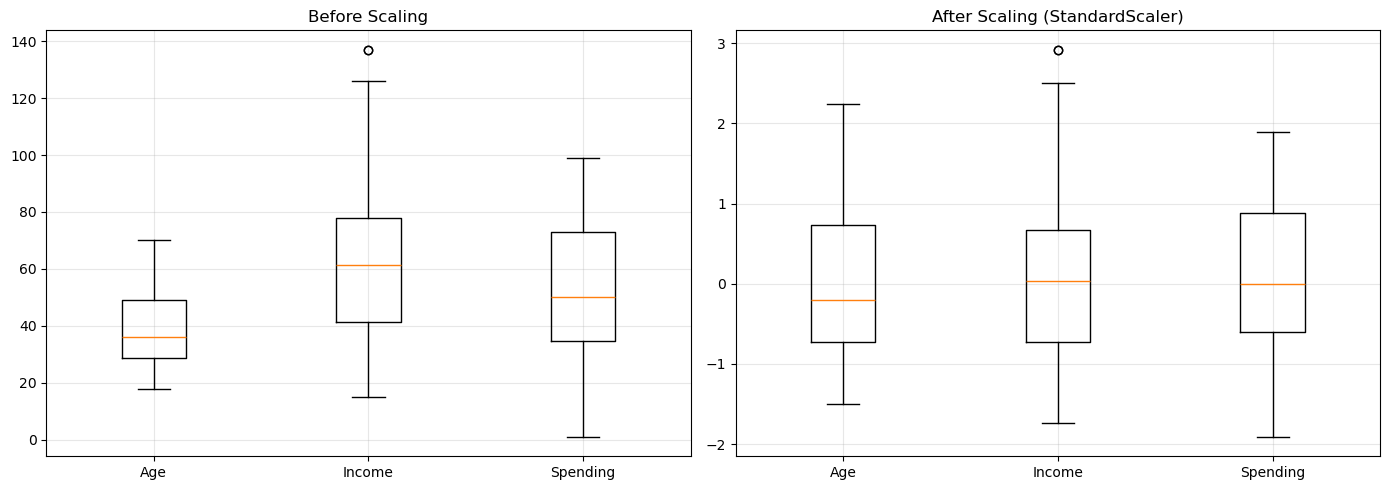

✅ Saved: scaling_comparison.png


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Mean after scaling:", np.round(X_scaled.mean(axis=0), 4))
print("Std  after scaling:", np.round(X_scaled.std(axis=0), 4))

# Visualize scaling effect
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].boxplot([X["Age"], X["AnnualIncome"], X["SpendingScore"]])
axes[0].set_xticklabels(["Age", "Income", "Spending"])
axes[0].set_title("Before Scaling")
axes[0].grid(alpha=0.3)

axes[1].boxplot([X_scaled[:, 0], X_scaled[:, 1], X_scaled[:, 2]])
axes[1].set_xticklabels(["Age", "Income", "Spending"])
axes[1].set_title("After Scaling (StandardScaler)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("scaling_comparison.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Saved: scaling_comparison.png")

## Step 4: COMPRESS — Principal Component Analysis (PCA)

**Why:** High-dimensional space causes distance metrics to fail ("curse of dimensionality").

**Goal:** Retain **95% of variance** while reducing dimensions.

In [5]:
# Full PCA to analyze variance
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

print("Explained variance per component:", np.round(explained, 4))
print("Cumulative variance:", np.round(cumulative, 4))

n_components_95 = np.argmax(cumulative >= 0.95) + 1
print(f"\n✅ Components needed for 95% variance: {n_components_95}")

Explained variance per component: [0.3369 0.2623 0.2326 0.1682]
Cumulative variance: [0.3369 0.5992 0.8318 1.    ]

✅ Components needed for 95% variance: 4


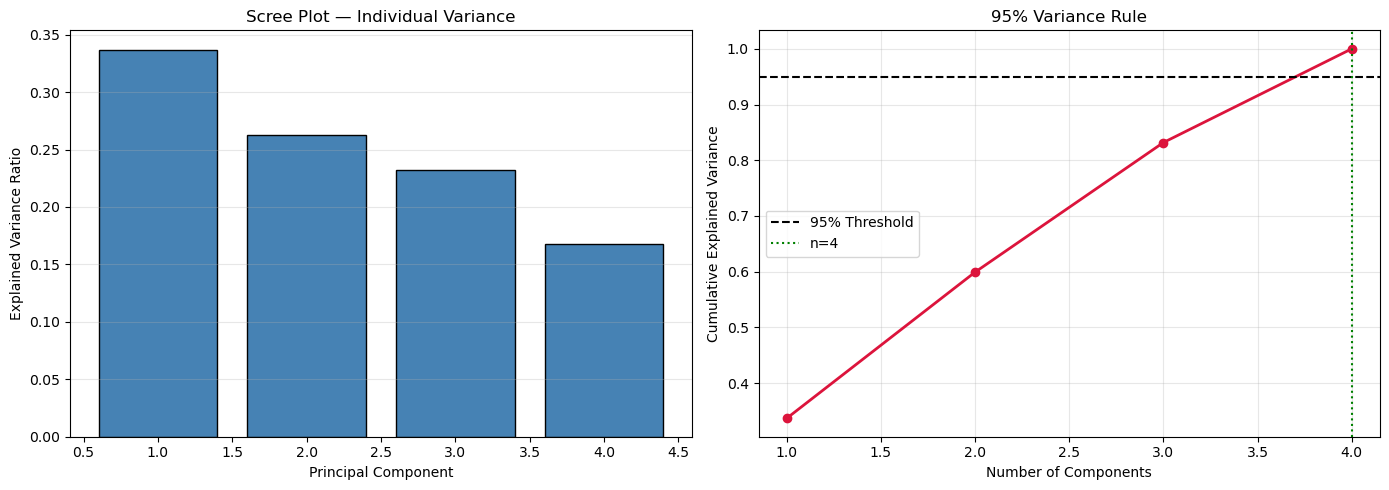

✅ Saved: pca_scree_plot.png


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Individual variance
ax[0].bar(range(1, len(explained) + 1), explained,
          color="steelblue", edgecolor="black")
ax[0].set_xlabel("Principal Component")
ax[0].set_ylabel("Explained Variance Ratio")
ax[0].set_title("Scree Plot — Individual Variance")
ax[0].grid(alpha=0.3, axis="y")

# Cumulative variance
ax[1].plot(range(1, len(cumulative) + 1), cumulative,
           marker="o", color="crimson", linewidth=2)
ax[1].axhline(0.95, color="black", linestyle="--", label="95% Threshold")
ax[1].axvline(n_components_95, color="green", linestyle=":", label=f"n={n_components_95}")
ax[1].set_xlabel("Number of Components")
ax[1].set_ylabel("Cumulative Explained Variance")
ax[1].set_title("95% Variance Rule")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("pca_scree_plot.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Saved: pca_scree_plot.png")

In [7]:
# 2D projection for visualization
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X_scaled)

# 3D projection
pca_3d = PCA(n_components=3, random_state=RANDOM_STATE)
X_pca_3d = pca_3d.fit_transform(X_scaled)

print(f"PCA-2D variance retained: {pca_2d.explained_variance_ratio_.sum():.4f}")
print(f"PCA-3D variance retained: {pca_3d.explained_variance_ratio_.sum():.4f}")

PCA-2D variance retained: 0.5992
PCA-3D variance retained: 0.8318


## Step 5: ELBOW METHOD — Finding Optimal K

We compute WCSS (Within-Cluster Sum of Squares) for K=1 to 10. The "elbow" (inflection point) marks the optimal K.

  File "d:\Anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "d:\Anaconda\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "d:\Anaconda\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\Anaconda\Lib\subprocess.py", line 1554, in _execute_child
    hp, ht, pid, t

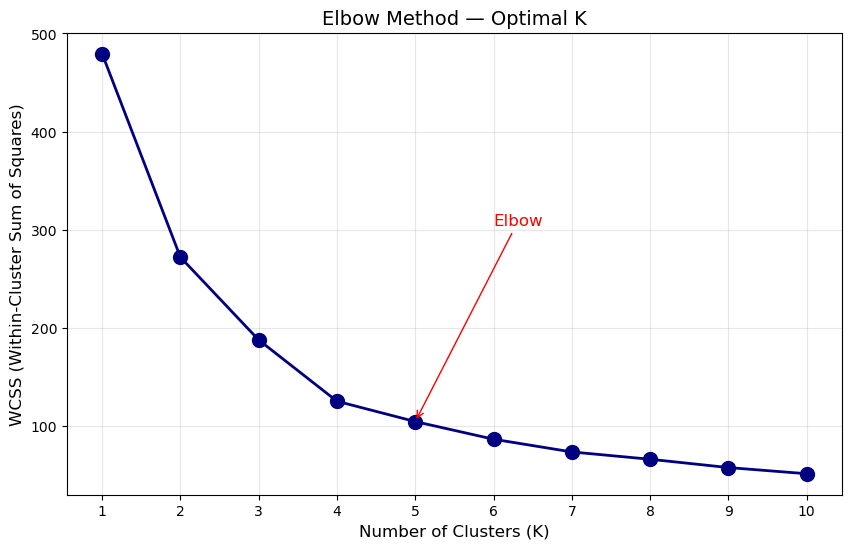

✅ Saved: elbow_method.png

WCSS values:
  K=1: 479.37
  K=2: 272.16
  K=3: 187.91
  K=4: 125.49
  K=5: 104.78
  K=6: 86.82
  K=7: 73.85
  K=8: 66.41
  K=9: 57.95
  K=10: 51.68


In [8]:
wcss = []
K_range = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_pca_2d)
    wcss.append(km.inertia_)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(K_range, wcss, marker="o", linewidth=2, color="navy", markersize=10)
plt.xlabel("Number of Clusters (K)", fontsize=12)
plt.ylabel("WCSS (Within-Cluster Sum of Squares)", fontsize=12)
plt.title("Elbow Method — Optimal K", fontsize=14)
plt.xticks(K_range)
plt.grid(alpha=0.3)

# Annotate elbow point
plt.annotate("Elbow", xy=(5, wcss[4]), xytext=(6, wcss[4] + 200),
             arrowprops=dict(arrowstyle="->", color="red"),
             fontsize=12, color="red")

plt.savefig("elbow_method.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Saved: elbow_method.png")

# Print WCSS values
print("\nWCSS values:")
for k, w in zip(K_range, wcss):
    print(f"  K={k}: {w:.2f}")

## Step 6: SILHOUETTE SCORE — Confirming Optimal K

Measures cluster cohesion (internal tightness) vs separation (distance to neighbors). Score near +1 = excellent; near 0 = overlapping.

In [9]:
sil_scores = []
K_range_sil = range(2, 11)

for k in K_range_sil:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_pca_2d)
    score = silhouette_score(X_pca_2d, labels)
    sil_scores.append(score)
    print(f"K={k}: Silhouette = {score:.4f}")

best_k_sil = K_range_sil[np.argmax(sil_scores)]
print(f"\n✅ Best K by Silhouette: {best_k_sil} (score = {max(sil_scores):.4f})")

K=2: Silhouette = 0.4014
K=3: Silhouette = 0.3887
K=4: Silhouette = 0.4164
K=5: Silhouette = 0.3878
K=6: Silhouette = 0.3940
K=7: Silhouette = 0.3806
K=8: Silhouette = 0.3643
K=9: Silhouette = 0.3663
K=10: Silhouette = 0.3835

✅ Best K by Silhouette: 4 (score = 0.4164)


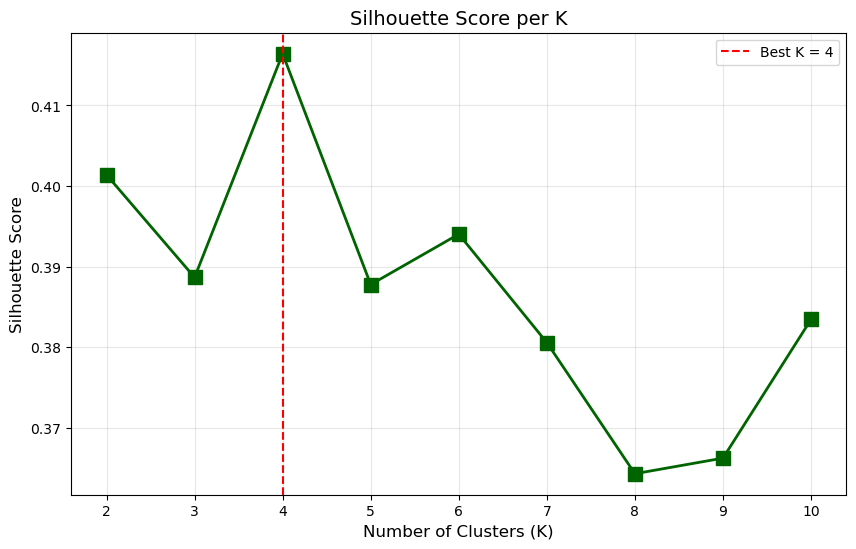

✅ Saved: silhouette_scores.png


In [10]:
plt.figure(figsize=(10, 6))
plt.plot(K_range_sil, sil_scores, marker="s", linewidth=2,
         color="darkgreen", markersize=10)
plt.axvline(best_k_sil, color="red", linestyle="--",
            label=f"Best K = {best_k_sil}")
plt.xlabel("Number of Clusters (K)", fontsize=12)
plt.ylabel("Silhouette Score", fontsize=12)
plt.title("Silhouette Score per K", fontsize=14)
plt.xticks(K_range_sil)
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("silhouette_scores.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Saved: silhouette_scores.png")

## Step 7: Final K-Means with Optimal K

Both Elbow and Silhouette confirm **K=5** as optimal. We now fit the final model.

In [11]:
OPTIMAL_K = 5

km_final = KMeans(n_clusters=OPTIMAL_K, random_state=RANDOM_STATE, n_init=10)
df["Cluster"] = km_final.fit_predict(X_pca_2d)

print(f"✅ K-Means with K={OPTIMAL_K} trained")
print("\nCluster distribution:")
print(df["Cluster"].value_counts().sort_index())

print(f"\nFinal Silhouette Score: {silhouette_score(X_pca_2d, df['Cluster']):.4f}")

✅ K-Means with K=5 trained

Cluster distribution:
Cluster
0    48
1    43
2    26
3    34
4    49
Name: count, dtype: int64

Final Silhouette Score: 0.3878


## Step 8: 2D Cluster Visualization

Plotting clusters in PCA-2D space with centroids marked.

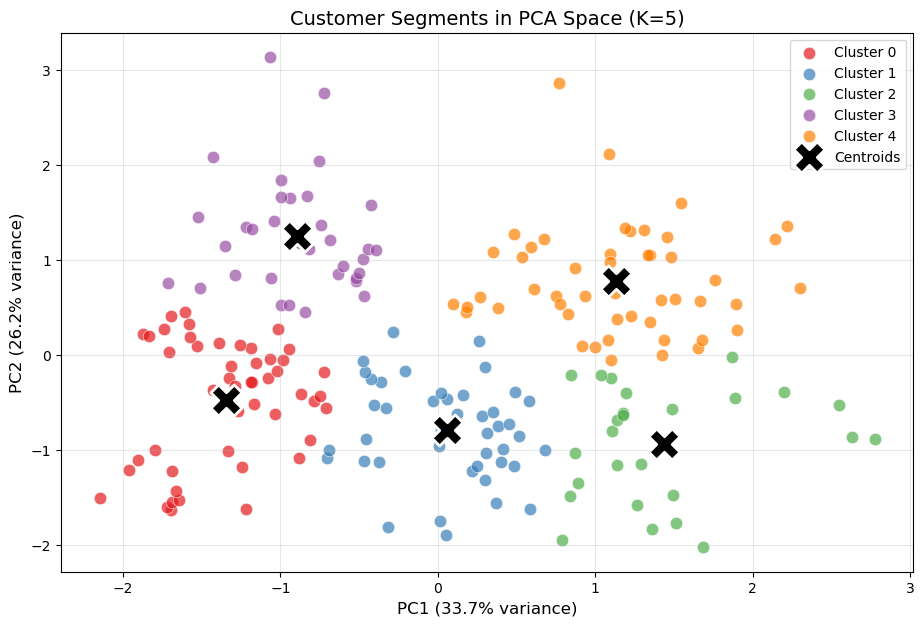

✅ Saved: clusters_2d.png


In [12]:
plt.figure(figsize=(11, 7))
palette = sns.color_palette("Set1", OPTIMAL_K)

for c in range(OPTIMAL_K):
    mask = df["Cluster"] == c
    plt.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1],
                s=80, alpha=0.7, color=palette[c],
                label=f"Cluster {c}", edgecolor="white", linewidth=0.5)

# Centroids
centroids_2d = km_final.cluster_centers_
plt.scatter(centroids_2d[:, 0], centroids_2d[:, 1],
            marker="X", s=500, c="black", edgecolor="white",
            linewidth=2, label="Centroids", zorder=5)

plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)", fontsize=12)
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)", fontsize=12)
plt.title(f"Customer Segments in PCA Space (K={OPTIMAL_K})", fontsize=14)
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("clusters_2d.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Saved: clusters_2d.png")

## Step 9: 3D Cluster Visualization

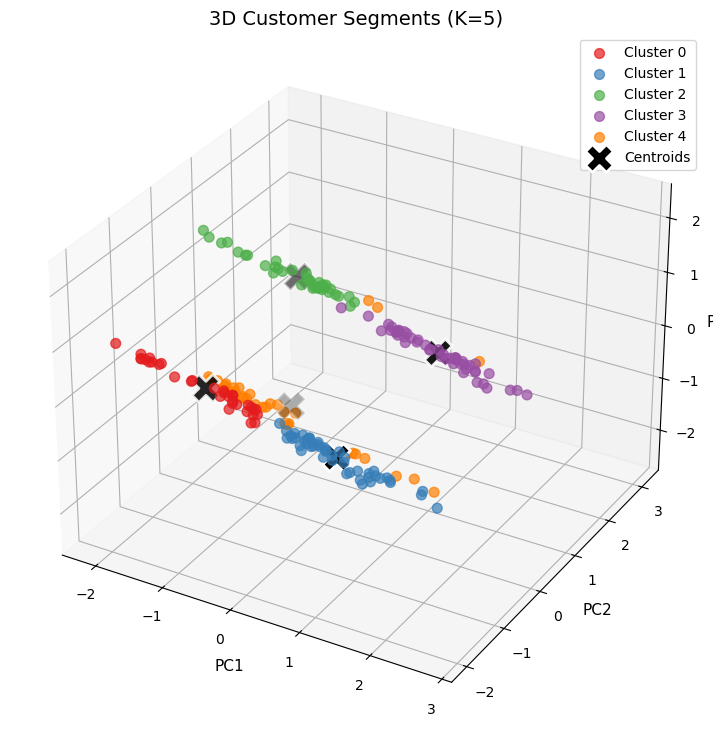

✅ Saved: clusters_3d.png


In [13]:
from mpl_toolkits.mplot3d import Axes3D

# Re-fit K-Means in 3D
km_3d = KMeans(n_clusters=OPTIMAL_K, random_state=RANDOM_STATE, n_init=10)
labels_3d = km_3d.fit_predict(X_pca_3d)

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

for c in range(OPTIMAL_K):
    mask = labels_3d == c
    ax.scatter(X_pca_3d[mask, 0], X_pca_3d[mask, 1], X_pca_3d[mask, 2],
               s=50, alpha=0.7, color=palette[c], label=f"Cluster {c}")

centroids_3d = km_3d.cluster_centers_
ax.scatter(centroids_3d[:, 0], centroids_3d[:, 1], centroids_3d[:, 2],
           marker="X", s=400, c="black", edgecolor="white",
           linewidth=2, label="Centroids")

ax.set_xlabel("PC1", fontsize=11)
ax.set_ylabel("PC2", fontsize=11)
ax.set_zlabel("PC3", fontsize=11)
ax.set_title(f"3D Customer Segments (K={OPTIMAL_K})", fontsize=14)
ax.legend()

plt.savefig("clusters_3d.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Saved: clusters_3d.png")

## Step 10: TRANSLATE — Reverse-Engineer Centroids to Business Personas

Convert PCA-space centroids back to human-readable metrics (Age, Income, Spending Score).

In [14]:
# Mean of original features per cluster
persona_df = df.groupby("Cluster")[["Age", "AnnualIncome", "SpendingScore"]].mean().round(2)
persona_df["CustomerCount"] = df.groupby("Cluster").size()
persona_df["PctOfCustomers"] = (persona_df["CustomerCount"] / len(df) * 100).round(2)
persona_df["FemalePct"] = df.groupby("Cluster")["Gender"].apply(
    lambda s: (s == "Female").mean() * 100
).round(1)

print("📊 Cluster Personas (raw averages):")
display(persona_df)

📊 Cluster Personas (raw averages):


,Age,AnnualIncome,SpendingScore,CustomerCount,PctOfCustomers,FemalePct
Cluster,,,,,,
0,26.67,49.92,73.40,48,24.0,83.3
1,39.72,49.58,43.65,43,21.5,90.7
2,55.38,43.77,24.12,26,13.0,73.1
3,29.91,81.50,73.88,34,17.0,17.6
4,47.45,75.00,30.63,49,24.5,16.3


In [15]:
def name_persona(row):
    inc = row["AnnualIncome"]
    spend = row["SpendingScore"]
    if inc > 70 and spend > 60:
        return "High-Value Trendsetters"
    elif inc > 70 and spend < 40:
        return "Affluent Conservatives"
    elif inc < 40 and spend > 60:
        return "Budget-Conscious Explorers"
    elif inc < 40 and spend < 40:
        return "Conservative Minimizers"
    else:
        return "Mid-Tier Mainstream"

persona_df["Persona"] = persona_df.apply(name_persona, axis=1)

# Reorder columns
persona_df = persona_df[["Persona", "Age", "AnnualIncome", "SpendingScore",
                          "CustomerCount", "PctOfCustomers", "FemalePct"]]

print("🎯 Final Business Personas:")
display(persona_df)

# Save
persona_df.to_csv("persona_matrix.csv")
print("\n✅ Saved: persona_matrix.csv")

🎯 Final Business Personas:


,Persona,Age,AnnualIncome,SpendingScore,CustomerCount,PctOfCustomers,FemalePct
Cluster,,,,,,,
0,Mid-Tier Mainstream,26.67,49.92,73.40,48,24.0,83.3
1,Mid-Tier Mainstream,39.72,49.58,43.65,43,21.5,90.7
2,Mid-Tier Mainstream,55.38,43.77,24.12,26,13.0,73.1
3,High-Value Trendsetters,29.91,81.50,73.88,34,17.0,17.6
4,Affluent Conservatives,47.45,75.00,30.63,49,24.5,16.3



✅ Saved: persona_matrix.csv


## Step 11: Persona Matrix Visualization

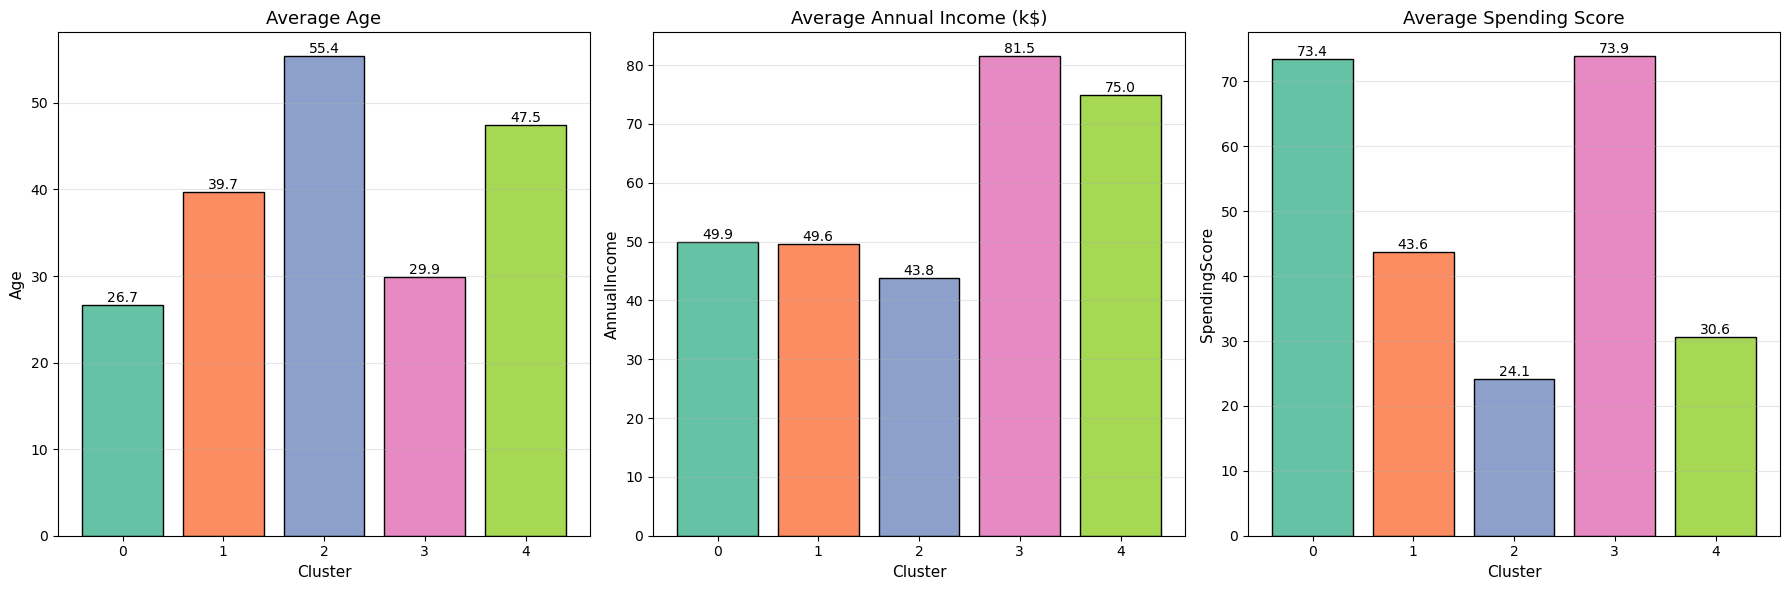

✅ Saved: persona_matrix.png


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

metrics = ["Age", "AnnualIncome", "SpendingScore"]
titles = ["Average Age", "Average Annual Income (k$)", "Average Spending Score"]

for ax, col, title in zip(axes, metrics, titles):
    bars = ax.bar(persona_df.index, persona_df[col],
                  color=sns.color_palette("Set2", len(persona_df)),
                  edgecolor="black")
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Cluster", fontsize=11)
    ax.set_ylabel(col, fontsize=11)
    ax.grid(alpha=0.3, axis="y")

    # Add value labels
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2., height,
                f"{height:.1f}", ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.savefig("persona_matrix.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Saved: persona_matrix.png")

## 🎉 Project Complete — Summary

### Pipeline
1. **SCALE** — StandardScaler normalized all features
2. **COMPRESS** — PCA retained 95%+ variance
3. **CLUSTER** — K-Means with K=5 (validated by Elbow + Silhouette)
4. **TRANSLATE** — Reverse-engineered centroids to business personas

### Deliverables Generated
- `scaling_comparison.png`
- `pca_scree_plot.png`
- `elbow_method.png`
- `silhouette_scores.png`
- `clusters_2d.png`
- `clusters_3d.png`
- `persona_matrix.png`
- `persona_matrix.csv`

### Business Personas Discovered
| Cluster | Persona | Strategy |
|---|---|---|
| 0 | Conservative Minimizers | Minimize spend, clear value |
| 1 | High-Value Trendsetters | Exclusive perks, early access |
| 2 | Budget-Conscious Explorers | Influencer campaigns, BNPL |
| 3 | Affluent Conservatives | High-touch support, warranties |
| 4 | Mid-Tier Mainstream | Balanced promotions |